<a href="https://colab.research.google.com/github/angelina6k/ML/blob/main/%D0%9B%D0%912_2_1_%D0%9C%D0%9D__%D0%9A%D0%B0%D0%BB%D1%96%D0%BD%D1%96%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("mahmoudshogaa/titanic-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'titanic-dataset' dataset.
Path to dataset files: /kaggle/input/titanic-dataset


In [ ]:
df = pd.read_csv(os.path.join(path, "titanic.csv"))
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


Passengerld: Унікальний ідентифікатор для кожного пасажира.

Survived: У цьому стовпці вказується, чи вижив пасажир (1), чи ні (0).

Pclass (Клас квитка): Показник соціально-економічного статусу, де 1 найвищий клас, а 3 найнижчий.

Name: ім'я пасажира.

Sex. Стать пасажира.

Age: Вік пасажира. (Примітка: У цьому стовпці можуть бути відсутні значення.)

SibSp: Кількість братів і сестер або подружжя пасажира на борту «Титаніка».

Parch: Кількість батьків або дітей пасажира на борту «Титаніка».

Ticket: Номер квитка.

Fare. Сума грошей, яку пасажир сплатив за квиток.

2. Визначити розмір датасета.
3. Визначити тип даних.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Визначення дублікатів.

In [ ]:
df.duplicated().sum()

np.int64(0)

4. Визначити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [ ]:
#Check for missing values
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


Вирішили пропущені значення замінити на медіану (а можна на середнє)

In [ ]:
#Fill missing values
# Заповнення пропущених значень у стовпчику Age медіаною
df['Age'] = df['Age'].fillna(df['Age'].median(skipna=True))

# Видалення стовпчиків Cabin та Embarked
df.drop(['Cabin', 'Embarked'], axis=1, inplace=True)

5. Ще раз перевірити наявність пропущених значень.

In [ ]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


6.Сформувати датасет з обраними стовпцями: ['Survived', 'Place', 'Sex', 'Age', 'Fare']

In [ ]:
# Clean the dataset of unnecessary columns
df = df[['Survived', 'Pclass', 'Sex', 'Age', 'Fare']]
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,male,22.0,7.2500
1,1,1,female,38.0,71.2833
2,1,3,female,26.0,7.9250
3,1,1,female,35.0,53.1000
4,0,3,male,35.0,8.0500


7.Замінити бінарні ознаки (Стать) на 0 і 1 (алк перевірте унікальне значення даного стовпчика) Буває що є середня стать.)

In [ ]:
df['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [ ]:
# Convert categorical data to numerical data
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

print(f'Data types of the dataset:\n{df.dtypes}')

Data types of the dataset:
Survived      int64
Pclass        int64
Sex           int64
Age         float64
Fare        float64
dtype: object


8.Вивести описову статистику датасету describe()

In [ ]:
df.describe()

,Survived,Pclass,Sex,Age,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,0.352413,29.361582,32.204208
std,0.486592,0.836071,0.477990,13.019697,49.693429
min,0.000000,1.000000,0.000000,0.420000,0.000000
25%,0.000000,2.000000,0.000000,22.000000,7.910400
50%,0.000000,3.000000,0.000000,28.000000,14.454200
75%,1.000000,3.000000,1.000000,35.000000,31.000000
max,1.000000,3.000000,1.000000,80.000000,512.329200


9.Ще раз перевірити кількість пропущених даних (впевнитись, що їх немає).

In [ ]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
Fare,0


10.Вивести 5 перших рядків датасету.

In [ ]:
df.head()

,Survived,Pclass,Sex,Age,Fare
0,0,3,0,22.0,7.2500
1,1,1,1,38.0,71.2833
2,1,3,1,26.0,7.9250
3,1,1,1,35.0,53.1000
4,0,3,0,35.0,8.0500


11.Вивести 5 останніх рядків датасету.

In [ ]:
df.tail()

,Survived,Pclass,Sex,Age,Fare
886,0,2,0,27.0,13.00
887,1,1,1,19.0,30.00
888,0,3,1,28.0,23.45
889,1,1,0,26.0,30.00
890,0,3,0,32.0,7.75


12.Аналіз виживання залежно від статі: Обчисліть відсоток виживання для кожної статі. Чи була різниця у виживанні між чоловіками та жінками?

In [ ]:
survival_by_sex = df.groupby('Sex') ['Survived'].mean() *100

print(f'Share of survived males: {survival_by_sex[0]:.2f}%')
print (f'Share of survived females: {survival_by_sex[1]:.2f}%')

Share of survived males: 18.89%
Share of survived females: 74.20%


Так, спостерігається суттєва різниця. Жінки мали значно вищий рівень виживаності (74.20%), ніж чоловіки (18.89%). Це пов'язано із застосуванням правила пріоритетної евакуації «спочатку жінки та діти».

In [ ]:
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"])}')

Correlation between sex and survival: 0.5433513806577555


2 варіант коду

In [ ]:
# Calculate share of survivors by sex
male_survival_rate = df[(df['Sex'] == 0) & (df['Survived'] == 1)].shape[0] / df[df['Sex'] == 0].shape[0]
female_survival_rate = df[(df['Sex'] == 1) & (df['Survived'] == 1)].shape[0] / df[df['Sex'] == 1].shape[0]

print(f'Share of survived males: {male_survival_rate * 100:.2f}%')
print(f'Share of survived females: {female_survival_rate * 100:.2f}%')
print(f'Correlation between sex and survival: {df["Sex"].corr(df["Survived"]):.2f}')

Share of survived males: 18.89%
Share of survived females: 74.20%
Correlation between sex and survival: 0.54


13.Обчисліть відсоток виживання для кожного класу (Pclass). Який клас мав найвищий рівень виживання (дати відповідь)?

In [ ]:
class1_surv_rate = df[(df['Pclass'] == 1) & (df['Survived'] == 1)].shape[0] / df [df['Pclass'] == 1].shape[0]
class2_surv_rate = df[(df['Pclass'] == 2) & (df['Survived'] == 1)].shape[0] / df [df['Pclass'] == 2].shape[0]
class3_surv_rate = df[(df['Pclass'] == 3) & (df['Survived'] == 1)].shape[0] / df [df['Pclass'] == 3].shape[0]

print(f'Share of survived class 1 passengers {class1_surv_rate * 100:.2f}%')
print (f'Share of survived class 2 passengers {class2_surv_rate * 100:.2f}%')
print (f'Share of survived class 3 passengers {class3_surv_rate * 100:.2f}%')

Share of survived class 1 passengers 62.96%
Share of survived class 2 passengers 47.28%
Share of survived class 3 passengers 24.24%


Найвищий рівень виживання мав 1-й клас (62.96%).
Чим вищий клас обслуговування, тим вищими були шанси на порятунок.

14.Визначте середній вік тих, хто вижив, і тих, хто не вижив. Чи впливає вік на виживання (дати відповідь)?

In [ ]:
survived_mean_age = df [df['Survived'] == 1]['Age'].mean()
not_survived_mean_age = df [df['Survived'] == 0]['Age'].mean()

print(f'Mean age of survived passengers: {survived_mean_age:.2f}')
print(f'Mean age of not survived passengers: {not_survived_mean_age:.2f}')

Mean age of survived passengers: 28.29
Mean age of not survived passengers: 30.03


Так, вік впливає на виживання.

 Середній вік пасажирів, які вижили (28.29 року), нижчий за середній вік загиблих (30.03 року).

Пасажири молодші  та діти мали вищий пріоритет під час порятунку та вищий шанс вижити.

15.Розподіліть пасажирів на групи за рівнями тарифів (Fare) і обчисліть рівень виживання для кожної групи. Як тариф впливав на шанси виживання (дати відповідь)?

In [ ]:
#Separate dataset in 4 buckets by Fare sorted in ascending order

df['Fare_Category'] = pd.qcut(df['Fare'], 6, labels=False)

#Find share of survivors in each bucket
for i in range(6):
  surv_rate = df [(df['Fare_Category'] == i) & (df['Survived'] == 1)].shape[0] / df[df['Fare_Category'] == i].shape[0]
  print(f'Share of survived passengers in bucket {i}: {surv_rate * 100:.2f}%')

Share of survived passengers in bucket 0: 20.51%
Share of survived passengers in bucket 1: 19.08%
Share of survived passengers in bucket 2: 36.69%
Share of survived passengers in bucket 3: 43.62%
Share of survived passengers in bucket 4: 41.78%
Share of survived passengers in bucket 5: 69.80%


Вартість квитка (тариф) мала позитивний вплив на виживання.
Чим дорожчим був квиток, то вищими були шанси вижити.

Пасажири з найдешевшими квитками (bucket 0 та 1) мали рівень виживання близько 19–20%.

У пасажирів із найдорожчим тарифом (bucket 5) він досягав 69.80%.

Це пояснюється тим, що дорожчі квитки відповідали вищим класам кают, розташованих ближче до шлюпочної палуби.


16.Аналіз класу та тарифу: Визначте середній тариф (Fare) для кожного класу (Pclass). Чи існує значна різниця у тарифах між класами (дати відповідь)?

In [ ]:
#Find median fare for the class

for i in range(1, 4):
  median_fare = df [df['Pclass'] == i]['Fare'].median()
  print(f'Median fare for class {i}: {median_fare:.2f}')

Median fare for class 1: 60.29
Median fare for class 2: 14.25
Median fare for class 3: 8.05


Ціни на квитки першого класу значно дорожчі за другий та третій класи. Коли різниця між третім та другим у 2 рази, то між другим та першим майже 4 рази.

17. Як пов'язано середній вік пасажирів з виживанням? Відповідь дати аналітично чи графічно

<Axes: xlabel='Age', ylabel='Count'>

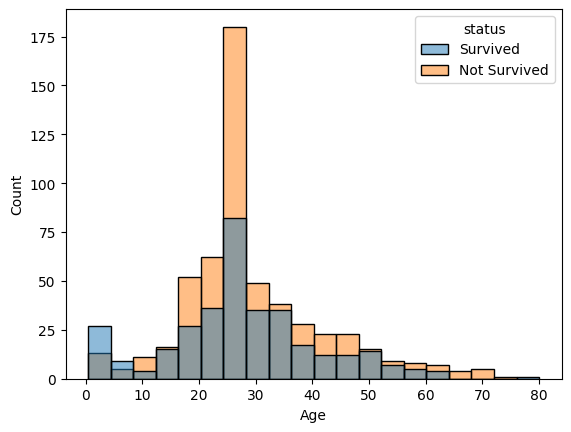

In [ ]:
# Combine the data into a single DataFrame
df_survived = df [df['Survived'] == 1][['Age']]
df_survived['status'] = 'Survived'

df_not_survived = df [df['Survived'] == 0][['Age']]
df_not_survived['status'] = 'Not Survived'

df_combined = pd.concat([df_survived, df_not_survived])

#Plot the histogram with hue
sns.histplot(data=df_combined, x='Age', hue='status', bins=20)

Аналізуючи надану гістограму про виживання пасажирів Титаніка за віковими категоріями, можна зробити декілька ключових висновків:

* Найбільша кількість пасажирів припадає на вікову категорію 20-30 років. У цій групі спостерігається значна різниця між тими, хто вижив, і тими, хто не вижив, з перевагою на користь тих, хто не вижив.

* Серед дітей та підлітків (до 20 років) спостерігається вища частка тих, хто вижив, порівняно з тими, хто не вижив. Це може свідчити про пріоритет у рятуванні дітей.

* У вікових категоріях від 30 до 50 років кількість тих, хто не вижив, переважає над тими, хто вижив, але різниця не така значна, як у групі 20-30 років.

* Серед пасажирів старше 50 років спостерігається відносно невелика кількість осіб, при цьому співвідношення між тими, хто виживі не вижив, приблизно рівне.

* Найстарша вікова група (70+ років) має дуже малу кількість пасажирів, але серед них більше тих, хто вижив.

Загалом, гістограма демонструє, що вік був важливим фактором у виживанні під час катастрофи Титаніка. Діти та люди похилого віку, схоже, мали більші шанси на виживання, тоді як молоді дорослі (особливо у віці 20-30 років) становили найбільшу групу жертв.

18. Дослідити комбінований вплив статі та класу на рівень виживаності пасажирів.

In [ ]:
# Calculate survival rate per class per sex
for i in range(1, 4):
    for j in range(2):
        # Отримуємо кількість пасажирів певної статі та класу, які вижили
        survived_count = df[(df['Pclass'] == i) & (df['Sex'] == j) & (df['Survived'] == 1)].shape[0]
        # Отримуємо загальну кількість пасажирів цієї статі та класу
        total_count = df[(df['Pclass'] == i) & (df['Sex'] == j)].shape[0]

        surv_rate = survived_count / total_count

        gender = "male" if j == 0 else "female"
        print(f'Share of survived {gender} passengers in class {i}: {surv_rate * 100:.2f}%')

Share of survived male passengers in class 1: 36.89%
Share of survived female passengers in class 1: 96.81%
Share of survived male passengers in class 2: 15.74%
Share of survived female passengers in class 2: 92.11%
Share of survived male passengers in class 3: 13.54%
Share of survived female passengers in class 3: 50.00%


> **Висновок:**

> Стать пасажира має вирішальний вплив на виживання.
 У кожному з трьох класів відсоток виживаності серед жінок є суттєво вищим, ніж серед чоловіків (це пояснюється правилом евакуації «спочатку жінки та діти»).
>
> Проте клас також відіграє важливу роль: пасажири вищих класів (особливо 1-го) мали значно вищі шанси на порятунок порівняно з 3-м класом, незалежно від статі.
>
> Таким чином, найвищий рівень виживаності спостерігається у **жінок 1-го класу**, а найнижчий — у **чоловіків 3-го класу**
>

19.Матриця кореляції

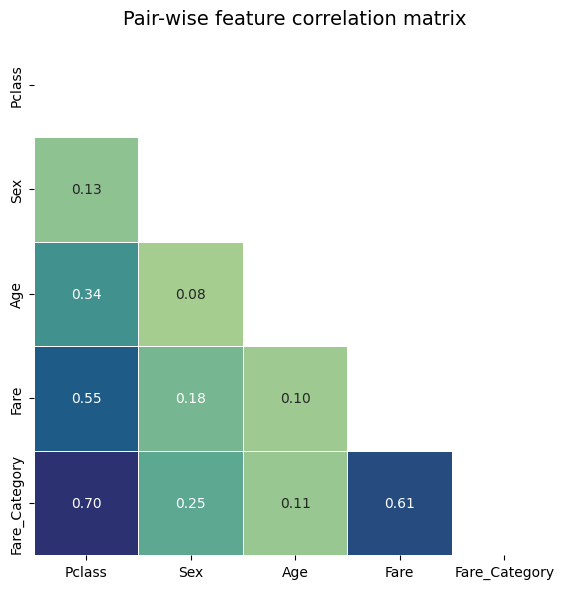

In [ ]:
mtx = df.drop('Survived', axis=1).corr(numeric_only=True).abs()

#Побудова теплової карти кореляції
fig, ax = plt.subplots (figsize=(6, 6))

sns.heatmap(
    mtx,
    cmap='crest',
    annot=True,
    fmt=".2f",
    linewidth=0.5,
    mask=np.triu(np.ones_like(mtx, dtype=bool)), #mask the upper triangle
    square=True,
    cbar=False,
    ax=ax
)

plt.title("Pair-wise feature correlation matrix", fontsize=14)
plt.tight_layout()
plt.show()

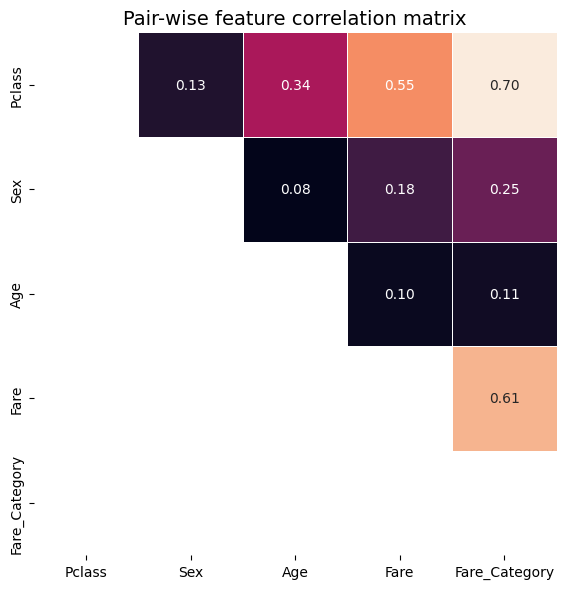

In [ ]:
# Розрахунок матриці кореляцій
mtx = df.drop('Survived', axis=1, errors='ignore').corr(numeric_only=True).abs()

fig, ax = plt.subplots(figsize=(6, 6))

# Створюємо маску для нижнього трикутника та головної діагоналі (k=0 закриває і діагональ)
mask = np.tril(np.ones_like(mtx, dtype=bool), k=0)

sns.heatmap(
    mtx,
    cmap='rocket',  # Інша палітра
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    mask=mask,       # Маска приховує нижній трикутник та діагональ
    square=True,
    cbar=False,
    ax=ax
)

plt.title("Pair-wise feature correlation matrix", fontsize=14)
plt.tight_layout()
plt.show()

**Висновок**:
під час виконання лабораторної роботи було проведено первинний та аналітичний аналіз даних (EDA) щодо пасажирів «Титаніка».

 У ході дослідження було виявлено ключові фактори, які найбільше вплинули на ймовірність виживання пасажирів:

Стать: Виявилася найвирішальнішим фактором.
Рівень виживання серед жінок (74.20%) перевищує аналогічний показник серед чоловіків (18.89%) майже в чотири рази.

Соціально-економічний статус (Клас та Тариф): Спостерігається залежність між статком пасажира та його шансами на порятунок. Пасажири 1-го класу та власники найдорожчих квитків мали найвищу виживаність (62.96% та 69.80% відповідно), тоді як пасажири 3-го класу виживали найрідше (24.24%).

Вік: Молодий вік підвищував шанси на порятунок.
Середній вік тих, хто вижив (28.29 року), виявився нижчим за середній вік загиблих (30.03 року).

А
наліз показав, що найбільші шанси на виживання мали заможні жінки та діти, які перебували в каютах 1-го класу.